# Tritium Breeding, Neutron Flux, Nuclear Heating and Radiation Damage in a Spherical Tokamak Blanket

## Notebook-2
This notebook studies the neutronics of a spherical tokamak fusion reactor using the Monte Carlo code **OpenMC** (version 0.16.0) with the **FENDL-3.2** nuclear data library. The model (`Spherical_tokamak_fendl`) is read from the XML files of the basic configuration (`materials.xml`, `geometry.xml` and `settings.xml`). No part of the geometry is changed here; only tallies are added and the results are processed.

This notebook is one part of a set. The text and code refer to companion notebooks for **SDDR** (shutdown dose rate) and **depletion** calculations, which use the same model and the same naming of components.

## Findings
A fusion power plant must breed its own tritium and must survive intense neutron radiation. This notebook answers four questions for the chosen design:

1. **TBR**:-The tritium breeding ratio (TBR) of the liquid Pb-Li blanket is **1.277 ± 0.0003** tritium atoms per source neutron. A value above 1 means that the blanket makes more tritium than the plasma burns. In practice, a margin is needed for losses, so a design must stay above 1.
2. **Fluence**:-The neutron flux is mapped in two dimensions (X–Z plane) and as a one-dimensional profile along the mid-plane. At the outer shield, the neutron fluence is **1.69 × 10¹⁸ n/cm² per full-power year**.
3. **Nuclear heating:-** Nuclear Heating (neutrons and photons together) is calculated for each component. The total deposited power is about **56.5 MW**. The breeding blanket takes the largest share (**42.1 MW**), followed by the protective shield (9.05 MW) and the first wall (4.33 MW).
4. **Structural damage:-** The average damage is given in displacements per atom (DPA) per full-power year. The first wall receives the highest damage (**2.04 DPA/FPY**), followed by the protective shield (0.21 DPA/FPY). The breeding blanket is a liquid, so DPA is not evaluated for it.

All results are scaled to a target neutron wall loading of 1.0 MW/m², which corresponds to a fusion power of 62.7 MW and a source strength of 2.225 × 10¹⁹ neutrons/s.


## Methodology

1. **Set-up.** The materials, geometry and settings of the basic model are loaded, and the cells are linked to Python variables by name.
2. **Tallies.** The following tallies are defined:
   * the TBR (`H3-production` in the blanket);
   * flux and heating for neutrons and for photons in every cell, plus a combined heating tally for all particles;
   * `damage-energy` for each nuclide in every cell;
   * mesh tallies (200 × 1 × 200 bins, 700 cm × 20 cm × 700 cm) for tritium production and neutron flux in the X–Z plane.
3. **Simulation.** A fixed-source calculation is run for 100 batches (about 10⁷ source neutrons). The leakage fraction is very small (0.00004), so almost all neutrons are stopped inside the model.
4. **Extraction.** Results are read from the statepoint file. Component volumes come from `geometry_dimensions.csv`. Mesh flux is divided by the bin volume (245 cm³) to give flux in n/cm² per source neutron.
5. **Normalisation.** Tallies are given per source neutron. They are multiplied by the source strength $S$, which is found from the target wall loading (1.0 MW/m²) and the first-wall area. One full-power year is taken as 3.1536 × 10⁷ s.
6. **Damage.** DPA is calculated with the Norgett-Robinson-Torrens (NRT) model. Only lattice atoms are counted (for example, tungsten but not boron in the WB₂ shield, and steel but not water in the reflector).
7. **Checks and output.** Neutron heating plus photon heating is compared with the combined heating tally. The plots and the final summary table (`Heating_and_Damage_Summary_Final.csv`) are saved in the results folder.

## Notes on Use

* DPA is a **volume average** for each component. It is not the peak value, which would be higher at the plasma-facing side.
* Heating and DPA values are results for one wall-loading case. They scale in direct proportion to the chosen wall loading.
* The folder names and file paths come from `config.py`, so this file must be present to run the notebook.

---


In [1]:
import openmc
import matplotlib.pyplot as plt
import os
import math
import re

import numpy as np
import pandas as pd
from matplotlib.colors import Normalize, LogNorm

from config import data_library, prefix, MODEL_NAME, BASE_DIR

In [2]:
print(MODEL_NAME)
print(BASE_DIR)

TBR_DIR = f"./{MODEL_NAME}_TBR+FLUX+HEATING+DAMAGE"
os.makedirs(TBR_DIR, exist_ok=True)

print(TBR_DIR)


Spherical_tokamak_fendl
./Spherical_tokamak_fendl_Basic_Configuration
./Spherical_tokamak_fendl_TBR+FLUX+HEATING+DAMAGE


In [3]:
# Clear OpenMC's memory of old IDs before loading new ones
openmc.reset_auto_ids()

# Apply the global library
openmc.config['cross_sections'] = data_library

# Loading materials FIRST from the base directory
original_mats_path = os.path.join(BASE_DIR, 'materials.xml')
materials = openmc.Materials.from_xml(original_mats_path)

# Passing the loaded materials directly into the geometry parser
geometry = openmc.Geometry.from_xml(
    os.path.join(BASE_DIR, 'geometry.xml'), 
    materials=materials
)

# Loading settings 
settings = openmc.Settings.from_xml(os.path.join(BASE_DIR, 'settings.xml'))


In [4]:
# Re-link the Python variables to the loaded cells
all_cells = geometry.get_all_cells()


for cell_id, c in all_cells.items():
    print(f"ID: {cell_id} | Name: '{c.name}'")


ID: 1 | Name: 'Copper Magnet Rod'
ID: 2 | Name: 'Protective Shield'
ID: 3 | Name: 'First Wall'
ID: 4 | Name: 'Breeding Blanket'
ID: 5 | Name: 'Reflector'
ID: 6 | Name: 'Outer Shield'
ID: 7 | Name: 'Plasma'
ID: 8 | Name: 'Vacuum Space'
ID: 9 | Name: 'Graveyard Void'


In [5]:
# Re-link the Python variables to the loaded cells using exact names
cell_cu = next(c for c in all_cells.values() if c.name == 'Copper Magnet Rod')
cell_shield = next(c for c in all_cells.values() if c.name == 'Protective Shield')
cell_fw = next(c for c in all_cells.values() if c.name == 'First Wall')
cell_blanket = next(c for c in all_cells.values() if c.name == 'Breeding Blanket')
cell_mirror = next(c for c in all_cells.values() if c.name == 'Reflector')
cell_outer = next(c for c in all_cells.values() if c.name == 'Outer Shield')
cell_plasma = next(c for c in all_cells.values() if c.name == 'Plasma')
cell_vac = next(c for c in all_cells.values() if c.name == 'Vacuum Space')
#cell_graveyard = next(c for c in all_cells.values() if c.name == 'Graveyard Void')

In [6]:
#  Cell Filters
# Specific blanket filter for TBR
blanket_filter = openmc.CellFilter(cell_blanket)
# Global filter for the component-wise heating/damage tallies
all_cells_list = list(all_cells.values())
global_cell_filter = openmc.CellFilter(all_cells_list)


In [7]:
# Particle Filters
neutron_filter = openmc.ParticleFilter('neutron')
photon_filter = openmc.ParticleFilter('photon')

In [8]:
# Mesh Filter
mesh = openmc.RegularMesh()
mesh.dimension = [200, 1, 200]
mesh.lower_left = [-350.0, -10.0, -350.0]
mesh.upper_right = [350.0, 10.0, 350.0]
mesh_filter = openmc.MeshFilter(mesh)

# Mesh numbers derived once from the mesh itself (same names as in the SDDR notebook)
nx, ny, nz = mesh.dimension
xl, yl, zl = mesh.lower_left
xu, yu, zu = mesh.upper_right
dx, dy, dz = (xu - xl) / nx, (yu - yl) / ny, (zu - zl) / nz
bin_volume = dx * dy * dz                         # cm^3 of one mesh bin, needed to turn track length into flux (245)
x_centres  = xl + (np.arange(nx) + 0.5) * dx      # bin centres along x
mid        = nz // 2                              # the two bins either side of z = 0


# `Tallies`

In [9]:
#  --------------  Bulk Tallies ---------------------------------
# TBR Tally
tbr_tally = openmc.Tally(name='TBR')
tbr_tally.filters = [blanket_filter, neutron_filter]
tbr_tally.scores = ['H3-production']

# Global Component Tallies 
comp_neutron_tally = openmc.Tally(name='All_Cells_Neutron')
comp_neutron_tally.filters = [global_cell_filter, neutron_filter]

comp_neutron_tally.scores = ['flux', 'heating']

#--------------------------------------------------------

'''
Note - Moved 'damage-energy' to a separate, nuclide-resolved tally to isolate radiation damage for specific structural metals within mixed materials. 
In blended components like the Tungsten-Boride shield or Steel-Water reflector, calculating crystal lattice damage (DPA) for liquids or light absorbers 
makes no physical sense. 
This setup filter out non-structural elements (like water or boron) and calculate the true DPA exclusively for the heavy atoms forming the 
solid metal framework.

'''
nuclide_names = sorted({nuc for m in materials for nuc in m.get_nuclides()})
comp_damage_tally = openmc.Tally(name='All_Cells_Damage')
comp_damage_tally.filters = [global_cell_filter, neutron_filter]
comp_damage_tally.scores = ['damage-energy']
comp_damage_tally.nuclides = nuclide_names + ['total']     # 'total' is kept for comparison

comp_gamma_tally = openmc.Tally(name='All_Cells_Gamma')
comp_gamma_tally.filters = [global_cell_filter, photon_filter]
comp_gamma_tally.scores = ['flux', 'heating']

# --- Combined Total Tally for accurate heating -------
comp_total_tally = openmc.Tally(name='All_Cells_Total')
comp_total_tally.filters = [global_cell_filter] 
comp_total_tally.scores = ['heating']

# ---------------------- Spatial Tallies ----------------------------
mesh_tbr_tally = openmc.Tally(name='TBR_Spatial')
mesh_tbr_tally.filters = [mesh_filter, neutron_filter]
mesh_tbr_tally.scores = ['H3-production']

mesh_flux_tally = openmc.Tally(name='Flux_Spatial')
mesh_flux_tally.filters = [mesh_filter, neutron_filter]
mesh_flux_tally.scores = ['flux']
#----------------------------------------------------------------------------------------------------
# Package and run
tallies = openmc.Tallies([
    tbr_tally, comp_neutron_tally, comp_damage_tally, comp_gamma_tally, comp_total_tally, 
    mesh_tbr_tally, mesh_flux_tally
])

In [10]:
model = openmc.Model(geometry=geometry, materials=materials, settings=settings, tallies=tallies)
statepoint_filename = model.run(cwd=TBR_DIR)

print(f"\nSimulation complete. All outputs saved to: {TBR_DIR}")

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

# `Data Extraction`

## Geometry Dimensions and Volumes

In [10]:
geom_df = pd.read_csv(os.path.join(BASE_DIR, 'geometry_dimensions.csv'), index_col="Component")

def dim(name, col):
    return float(geom_df.loc[name, col])

# Radii (cm)
r_cu_in       = dim("Copper Magnet Rod (Central)",  "Inner Radius (cm)")
r_cu_out      = dim("Copper Magnet Rod (Central)",  "Outer Radius (cm)")
r_shield_in   = dim("Protective Shield (Central)",  "Inner Radius (cm)")
r_shield_out  = dim("Protective Shield (Central)",  "Outer Radius (cm)")
r_fw_in       = dim("First Wall (Spherical)",       "Inner Radius (cm)")
r_fw_out      = dim("First Wall (Spherical)",       "Outer Radius (cm)")
r_blanket_in  = dim("Breeding Blanket (Spherical)", "Inner Radius (cm)")
r_blanket_out = dim("Breeding Blanket (Spherical)", "Outer Radius (cm)")
r_mirror_in   = dim("Steel Reflector (Spherical)",  "Inner Radius (cm)")
r_mirror_out  = dim("Steel Reflector (Spherical)",  "Outer Radius (cm)")
r_outer_in    = dim("Outer Shield (Spherical)",     "Inner Radius (cm)")
r_outer_out   = dim("Outer Shield (Spherical)",     "Outer Radius (cm)")

# The central column (Cu rod + shield) is capped by the outermost sphere,
# so its half-length equals that radius
z_bound = r_outer_out

# The spherical shells must touch each other
assert np.isclose(r_fw_out, r_blanket_in) and np.isclose(r_blanket_out, r_mirror_in) \
   and np.isclose(r_mirror_out, r_outer_in), "shell radii not contiguous - check geometry_dimensions.csv"

# Analytic volumes (cm^3)
vol_cu      = dim("Copper Magnet Rod (Central)",  "Volume (cm^3)")
vol_shield  = dim("Protective Shield (Central)",  "Volume (cm^3)")
vol_fw      = dim("First Wall (Spherical)",       "Volume (cm^3)")
vol_blanket = dim("Breeding Blanket (Spherical)", "Volume (cm^3)")
vol_mirror  = dim("Steel Reflector (Spherical)",  "Volume (cm^3)")
vol_outer   = dim("Outer Shield (Spherical)",     "Volume (cm^3)")

print(geom_df[['Inner Radius (cm)', 'Outer Radius (cm)', 'Volume (cm^3)']])
print(f"Column half-length z_bound = {z_bound} cm")

                             Inner Radius (cm)        Outer Radius (cm)  \
Component                                                                 
Copper Magnet Rod (Central)                0.0                     20.0   
Protective Shield (Central)               23.0                     53.0   
First Wall (Spherical)                   200.0                    201.0   
Breeding Blanket (Spherical)             201.0                    301.0   
Steel Reflector (Spherical)              301.0                    321.0   
Outer Shield (Spherical)                 321.0                    351.0   
Plasma Torus                    Major a: 126.5  Minor b: 100.0, c: 50.0   

                              Volume (cm^3)  
Component                                    
Copper Magnet Rod (Central)    8.814428e+05  
Protective Shield (Central)    4.994114e+06  
First Wall (Spherical)         4.872032e+05  
Breeding Blanket (Spherical)   7.843064e+07  
Steel Reflector (Spherical)    2.396142e+07  
Ou

## Components Table

In [20]:
# Components table (same names and order as in the SDDR and depletion notebooks): the cell and its analytic volume
components = {
    'Copper Magnet Rod': dict(cell=cell_cu,      vol=vol_cu),
    'Protective Shield': dict(cell=cell_shield,  vol=vol_shield),
    'First Wall':        dict(cell=cell_fw,      vol=vol_fw),
    'Breeding Blanket':  dict(cell=cell_blanket, vol=vol_blanket),
    'Reflector':         dict(cell=cell_mirror,  vol=vol_mirror),
    'Outer Shield':      dict(cell=cell_outer,   vol=vol_outer),
}

In [21]:
statepoint_filename = os.path.join(TBR_DIR, f'statepoint.{settings.batches}.h5')
with openmc.StatePoint(statepoint_filename) as sp:
    # Extracting TBR Data 
    mesh_tbr_result = sp.get_tally(name='TBR_Spatial')
    tbr_data = mesh_tbr_result.mean.reshape((nx, ny, nz), order='F')[:, 0, :]
    
    tbr_bulk_result = sp.get_tally(name='TBR')
    tbr_mean = tbr_bulk_result.mean.sum()
    tbr_std_dev = tbr_bulk_result.std_dev.sum()

    # Extracting Flux Data 
    mesh_flux_result = sp.get_tally(name='Flux_Spatial')
    flux_data = mesh_flux_result.mean.reshape((nx, ny, nz), order='F')[:, 0, :] / bin_volume     # n/cm^2 per source neutron

    
    # Extracting Global Component Tally
    neutron_tally = sp.get_tally(name='All_Cells_Neutron')
    df_n = neutron_tally.get_pandas_dataframe()

    damage_tally = sp.get_tally(name='All_Cells_Damage')
    df_dmg = damage_tally.get_pandas_dataframe()

    # Extracting Combined Heating Tally 
    total_tally = sp.get_tally(name='All_Cells_Total')
    df_total = total_tally.get_pandas_dataframe()
    
    # Isolate total heating and set cell ID as index for clean mapping
    heat_total_df = df_total[df_total['score'] == 'heating'].set_index('cell')
    total_heating_mean = heat_total_df['mean']
    total_heating_std = heat_total_df['std. dev.']

    # Isolate the Outer Shield flux from the neutron dataframe 
    outer_df = df_n[df_n['cell'] == cell_outer.id]
    outer_flux_row = outer_df[outer_df['score'] == 'flux']
    out_flux_mean = (outer_flux_row['mean'].values[0] / vol_outer) if not outer_flux_row.empty else 0.0
    out_flux_std  = (outer_flux_row['std. dev.'].values[0] / vol_outer) if not outer_flux_row.empty else 0.0

print(f"Tritium Breeding Ratio (TBR): {tbr_mean:.5f} ± {tbr_std_dev:.5f}")
print(f"Outer Shield Bulk Flux      : {out_flux_mean:.5e} ± {out_flux_std:.5e}\n")

Tritium Breeding Ratio (TBR): 1.27719 ± 0.00030
Outer Shield Bulk Flux      : 2.40456e-09 ± 1.88823e-11



**Flux normalisation:** OpenMC's `flux` score gives the total particle track length per source neutron (in cm), not the flux per unit volume. The mesh values are therefore divided by the bin volume (245 cm³), and the outer-shield value by its cell volume, to obtain the flux in n/cm² per source neutron. Multiplying by the source strength $S$ gives the flux in n/cm²/s, which is then converted to fluence per full-power year (FPY).

# `Plotting`

## Plot 1: TBR Heatmap

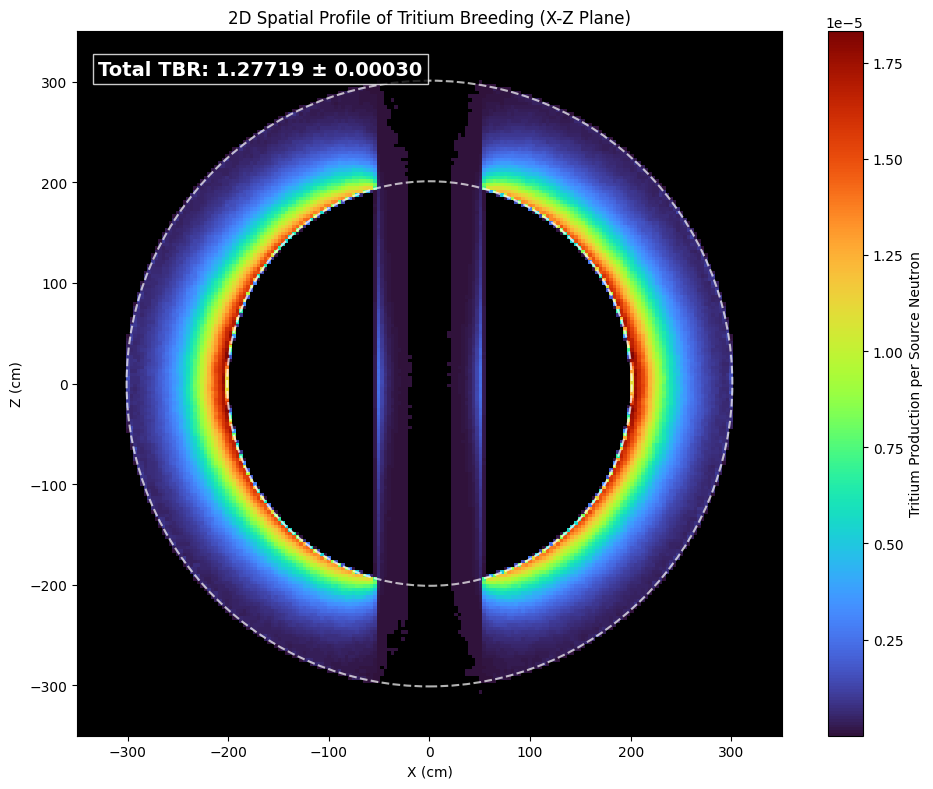

In [22]:

plt.figure(figsize=(10, 8))
ax1 = plt.gca()
ax1.set_facecolor('black')    

# Mask near-zero breeding
masked_tbr_data = np.ma.masked_where(tbr_data <= 1e-10, tbr_data)

# Heatmap
im1 = plt.imshow(masked_tbr_data.T, origin='lower', extent=[xl, xu, zl, zu], cmap='turbo')

plt.colorbar(im1, label='Tritium Production per Source Neutron')
plt.title('2D Spatial Profile of Tritium Breeding (X-Z Plane)')
plt.xlabel('X (cm)')
plt.ylabel('Z (cm)')

# Outlines for FW and Blanket
circle_fw = plt.Circle((0, 0), r_fw_out, color='white', fill=False, linestyle='--', linewidth=1.5, alpha=0.7)
circle_bl = plt.Circle((0, 0), r_blanket_out, color='white', fill=False, linestyle='--', linewidth=1.5, alpha=0.7)
ax1.add_patch(circle_fw)
ax1.add_patch(circle_bl)

# TBR Text Box
tbr_text = f"Total TBR: {tbr_mean:.5f} ± {tbr_std_dev:.5f}"
plt.text(0.03, 0.96, tbr_text, transform=ax1.transAxes, 
         fontsize=14, color='white', fontweight='bold',
         bbox=dict(facecolor='black', edgecolor='white', alpha=0.8),
         verticalalignment='top')
plt.tight_layout()

plt.tight_layout()

plot_filename = os.path.join(TBR_DIR, 'TBR_Spatial_Profile.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
plt.show()

## Plot 2: Neutron Flux Heatmap

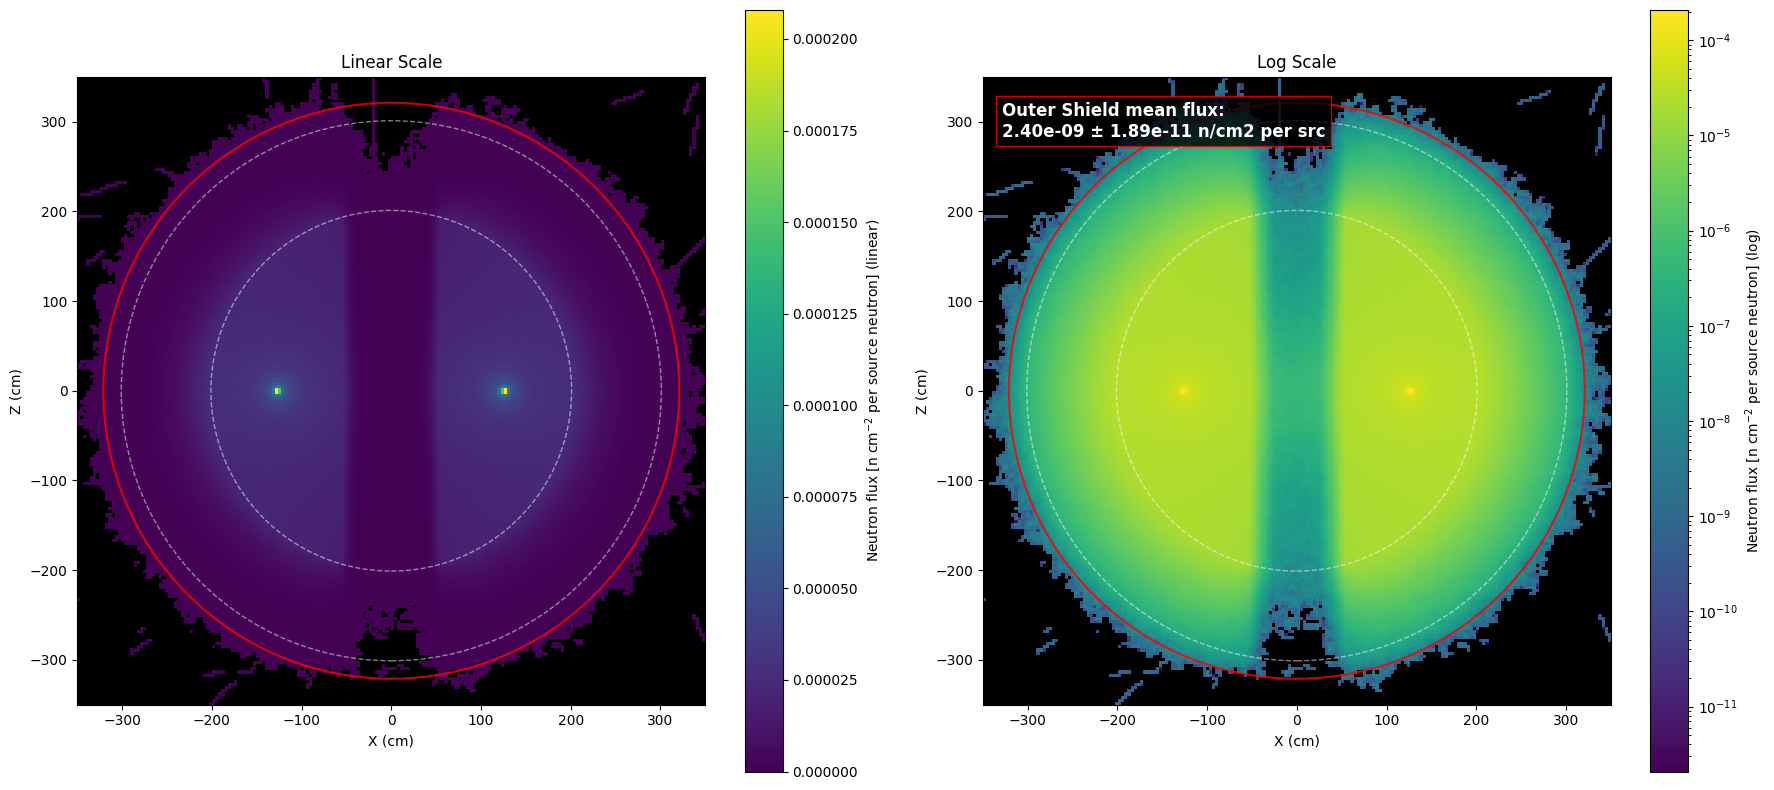

Plot saved to: ./Spherical_tokamak_fendl_TBR+FLUX+HEATING+DAMAGE/Neutron_Flux_Profile_Comparison.png


In [23]:

# Mask absolute zero values to prevent LogNorm errors
masked_flux_data = np.ma.masked_where(flux_data <= 0.0, flux_data)

# Create one figure for side-by-side comparison
fig = plt.figure(figsize=(18, 8))

# Linear sccale plot
# ******************************************************
ax1 = fig.add_subplot(1, 2, 1)
ax1.set_facecolor('black')

im1 = ax1.imshow(masked_flux_data.T, origin='lower', extent=[xl, xu, zl, zu], 
                 cmap='viridis', norm=Normalize(vmin=0, vmax=masked_flux_data.max()))

plt.colorbar(im1, ax=ax1, label='Neutron flux [n cm$^{-2}$ per source neutron] (linear)')
ax1.set_title('Linear Scale')
ax1.set_xlabel('X (cm)')
ax1.set_ylabel('Z (cm)')

# Outlines
ax1.add_patch(plt.Circle((0, 0), r_fw_out, color='white', fill=False, ls='--', lw=1.0, alpha=0.5))
ax1.add_patch(plt.Circle((0, 0), r_blanket_out, color='white', fill=False, ls='--', lw=1.0, alpha=0.5))
ax1.add_patch(plt.Circle((0, 0), r_outer_in, color='red', fill=False, ls='-', lw=1.5, alpha=0.8))


# Log Scale Plot
# **********************************************
# Assign to the right side of the existing figure
ax2 = fig.add_subplot(1, 2, 2)
ax2.set_facecolor('black')

im2 = ax2.imshow(masked_flux_data.T, origin='lower', extent=[xl, xu, zl, zu],
                 cmap='viridis', norm=LogNorm(vmin=masked_flux_data.max() * 1e-8, vmax=masked_flux_data.max()))
plt.colorbar(im2, ax=ax2, label='Neutron flux [n cm$^{-2}$ per source neutron] (log)')

ax2.set_title('Log Scale')
ax2.set_xlabel('X (cm)')
ax2.set_ylabel('Z (cm)')

# Outlines
ax2.add_patch(plt.Circle((0, 0), r_fw_out, color='white', fill=False, ls='--', lw=1.0, alpha=0.5))
ax2.add_patch(plt.Circle((0, 0), r_blanket_out, color='white', fill=False, ls='--', lw=1.0, alpha=0.5))
ax2.add_patch(plt.Circle((0, 0), r_outer_in, color='red', fill=False, ls='-', lw=1.5, alpha=0.8))


# Flux Text Box
flux_text = f"Outer Shield mean flux:\n{out_flux_mean:.2e} ± {out_flux_std:.2e} n/cm2 per src"
ax2.text(0.03, 0.96, flux_text, transform=ax2.transAxes, 
         fontsize=12, color='white', fontweight='bold',
         bbox=dict(facecolor='black', edgecolor='red', alpha=0.8),
         verticalalignment='top')

plt.tight_layout()

# Saving the combined figure to {path}
plot_filename = os.path.join(TBR_DIR, 'Neutron_Flux_Profile_Comparison.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')

plt.show()
print(f"Plot saved to: {plot_filename}")


## Plot 3: 1D Radial Profile of Neutron Flux

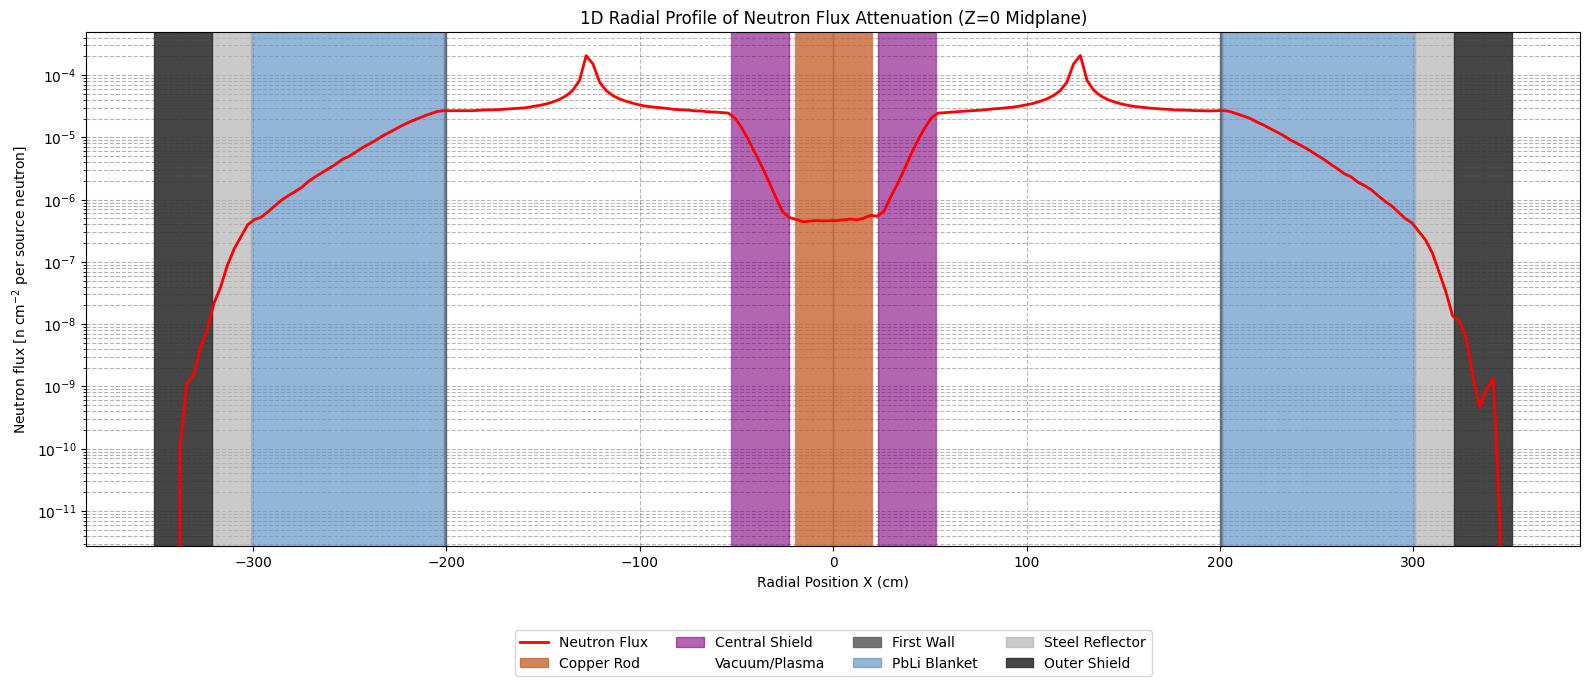

Dynamic 1D Profile saved to: ./Spherical_tokamak_fendl_TBR+FLUX+HEATING+DAMAGE/Neutron_Flux_1D_Radial_Profile_CSV.png


In [24]:
# COlours
shared_colors = {
    cell_cu:      (200, 100, 50),    # Copper Rod: Bronze/Orange
    cell_shield:  (128, 0, 128),     # Central Shield: Purple
    cell_fw:      (100, 100, 100),   # First Wall (1 cm): Dark Gray
    cell_blanket: (100, 150, 200),   # PbLi Blanket (100 cm): Light Blue
    cell_mirror:  (180, 180, 180),   # Steel Reflector (20 cm): Silver/Light Gray
    cell_outer:  (50, 50, 50),      # Outer Shield (30 cm): Black
    cell_plasma:  (255, 0, 0),       # Plasma Core: Red
    cell_vac:     (255, 255, 255)    # Vacuum Chamber: White
}

# Helper to format RGB for Matplotlib (converts 0-255 to 0.0-1.0)
def get_mpl_color(cell):
    r, g, b = shared_colors[cell]
    return (r / 255.0, g / 255.0, b / 255.0)


# Generate X-axis coordinates and extract mid-plane slice (Z=0)
flux_1d = 0.5 * (flux_data[:, mid - 1] + flux_data[:, mid])  # average of the two bins either side of z = 0   


# Create the Plot
plt.figure(figsize=(16, 7))
ax = plt.gca()
ax.set_facecolor('white')

plt.plot(x_centres, flux_1d, color='red', linewidth=2, label='Neutron Flux', zorder=5)

plt.yscale('log') 
plt.title('1D Radial Profile of Neutron Flux Attenuation (Z=0 Midplane)')
plt.xlabel('Radial Position X (cm)')
#plt.ylabel('Neutron Flux (per source particle)')
plt.ylabel('Neutron flux [n cm$^{-2}$ per source neutron]')
plt.grid(True, which="both", ls="--", alpha=0.3, color='black', zorder=1)

# Highlight Geometry Regions (Positive X)
plt.axvspan(0, r_cu_out, color=get_mpl_color(cell_cu), alpha=0.8, label='Copper Rod', zorder=2)

# Gap between Copper and Shield
plt.axvspan(r_cu_out, r_shield_in, color=get_mpl_color(cell_vac), alpha=0.1, zorder=2)
plt.axvspan(r_shield_in, r_shield_out, color=get_mpl_color(cell_shield), alpha=0.6, label='Central Shield', zorder=2)

# Vacuum/Plasma space
plt.axvspan(r_shield_out, r_fw_in, color=get_mpl_color(cell_vac), alpha=0.1, label='Vacuum/Plasma', zorder=2)

plt.axvspan(r_fw_in, r_fw_out, color=get_mpl_color(cell_fw), alpha=0.9, label='First Wall', zorder=2)
plt.axvspan(r_fw_out, r_blanket_out, color=get_mpl_color(cell_blanket), alpha=0.7, label='PbLi Blanket', zorder=2)
plt.axvspan(r_blanket_out, r_mirror_out, color=get_mpl_color(cell_mirror), alpha=0.7, label='Steel Reflector', zorder=2)
plt.axvspan(r_mirror_out, r_outer_out, color=get_mpl_color(cell_outer), alpha=0.9, label='Outer Shield', zorder=2)

# Mirror Side
plt.axvspan(-r_cu_out, 0, color=get_mpl_color(cell_cu), alpha=0.8, zorder=2)
plt.axvspan(-r_shield_in, -r_cu_out, color=get_mpl_color(cell_vac), alpha=0.1, zorder=2)
plt.axvspan(-r_shield_out, -r_shield_in, color=get_mpl_color(cell_shield), alpha=0.6, zorder=2)
plt.axvspan(-r_fw_in, -r_shield_out, color=get_mpl_color(cell_vac), alpha=0.1, zorder=2)

plt.axvspan(-r_fw_out, -r_fw_in, color=get_mpl_color(cell_fw), alpha=0.9, zorder=2)
plt.axvspan(-r_blanket_out, -r_fw_out, color=get_mpl_color(cell_blanket), alpha=0.7, zorder=2)
plt.axvspan(-r_mirror_out, -r_blanket_out, color=get_mpl_color(cell_mirror), alpha=0.7, zorder=2)
plt.axvspan(-r_outer_out, -r_mirror_out, color=get_mpl_color(cell_outer), alpha=0.9, zorder=2)

# Layout
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=4)
plt.tight_layout()

# Save and Display
plot_filename = os.path.join(TBR_DIR, 'Neutron_Flux_1D_Radial_Profile_CSV.png')
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
plt.show()

print(f"Dynamic 1D Profile saved to: {plot_filename}")

# `Heating and Damage Calculations`

## Physics Constants and Source Normalisation

### Source Strength Normalisation ($S$)

OpenMC records tallies per source particle. To convert them into physical units (Watts or DPA/year), the raw results must be multiplied by the total neutron source strength ($S$) of the reactor.

Instead of assuming an arbitrary power output, the source strength is calculated from a target Neutron Wall Loading (NWL). This gives a more realistic estimate of the structural damage. Typical NWL values for fusion designs are about 0.5–2 MW/m², and this notebook uses 1.0 MW/m².

In a Deuterium-Tritium (D-T) fusion reaction, each event produces a 14.1 MeV neutron and a 3.5 MeV alpha particle, releasing a total of 17.6 MeV. The neutron carries about 80% of this energy towards the first wall.

For a target NWL of 1.0 MW/m² and a spherical first wall with an inner radius of 2.0 m (200 cm), the source strength is found as follows:

**1. Calculate the plasma-facing area ($A$):**
$$A = 4 \pi r_{fw,in}^2 = 4 \pi (2.0)^2 = 50.27 \text{ m}^2$$

**2. Calculate the total fusion power ($P_{fusion}$):**
$$P_{fusion} = \frac{\text{NWL} \times A}{\text{Neutron Fraction}} = \frac{1.0 \times 10^6 \text{ W/m}^2 \times 50.27 \text{ m}^2}{14.1 / 17.6} = 62.74 \text{ MW}$$

**3. Calculate the neutron source strength ($S$):**
$$S = \frac{P_{fusion}}{17.6 \times 10^6 \text{ eV} \times 1.6022 \times 10^{-19} \text{ J/eV}}$$

$$S = \frac{62.74 \times 10^6 \text{ W}}{2.820 \times 10^{-12} \text{ J/reaction}} = 2.225 \times 10^{19} \text{ neutrons/second}$$

**References:**

* Abdou, M., et al. (2015). "Blanket/first wall challenges and required R&D on the pathway to DEMO." *Fusion Engineering and Design*, 100, 2–43.
* Federici, G., et al. (2014). "Overview of EU DEMO design and R&D activities." *Fusion Engineering and Design*, 89(7–8), 882–889.

In [25]:

N_A = 6.02214076e23        # Avogadro's number
seconds_per_fpy = 3.1536e7 # Seconds in 1 Full Power Year (365 days)
beta = 0.8                 # NRT model efficiency factor

#---- Source strength from a Target neutron Wall Loading 
target_nwl_MW_m2 = 1.0                          # realistic range 0.5 - 2 MW/m^2 (change this one number)
r_fw_inner_m = r_fw_in / 100.0                    # first-wall inner radius r_vac = 200 cm -> metres
fw_area_m2 = 4.0 * math.pi * r_fw_inner_m**2    # plasma-facing wall area  (~50.3 m^2)
neutron_fraction = 14.1 / 17.6                  # share of the fusion power carried by the neutron

fusion_power_watts = target_nwl_MW_m2 * 1e6 * fw_area_m2 / neutron_fraction   # ~63 MW 
joules_per_dt_reaction = 17.6e6 * 1.60217663e-19
source_strength = fusion_power_watts / joules_per_dt_reaction                 # ~2.2e19 n/s 

print(f"Fusion power {fusion_power_watts/1e6:.1f} MW ––> S = {source_strength:.3e} n/s "
      f"(wall loading {target_nwl_MW_m2} MW/m2 on {fw_area_m2:.1f} m2)")

Fusion power 62.7 MW ––> S = 2.225e+19 n/s (wall loading 1.0 MW/m2 on 50.3 m2)


### Fluence per FPY

In [26]:
fluence_per_fpy = out_flux_mean * source_strength * seconds_per_fpy
print(f"Outer Shield neutron fluence per full-power year: {fluence_per_fpy:.3e} n/cm^2")

Outer Shield neutron fluence per full-power year: 1.687e+18 n/cm^2


## Tally Extraction and Macroscopic Metrics

**Lattice atoms used for DPA.** The damage energy is tallied for each nuclide, and only the lattice nuclides are counted:

* Tungsten only in the WB₂ shield ($E_d$ = 90 eV is a tungsten value, so boron is excluded).
* Steel atoms only in the reflector (the hydrogen and oxygen of the water are excluded).
* All atoms in the copper rod and in the pure tungsten components (first wall and outer shield).

The number of atoms is taken from the OpenMC material (atom density × volume), so the density, composition and atom number cannot disagree.

| Component | Atoms used for DPA | E_d (eV) |
|---|---|---|
| Copper Magnet Rod | 7.49e28 (Cu) | 30 |
| Protective Shield | 1.90e29 (W only) | 90 |
| First Wall | 3.08e28 (W) | 90 |
| Breeding Blanket | not evaluated (liquid) | - |
| Reflector | 1.64e30 (steel only) | 40 |
| Outer Shield | 2.66e30 (W) | 90 |

(These values match the notebook output for the current materials and exact volumes. The notebook recalculates them itself.)

In [27]:
# Type of atoms that form the crystal lattice of each component (used for DPA)
#   Protective Shield (WB2) -> tungsten atoms only (Ed = 90 eV is a tungsten value)
#   Reflector (steel + water) -> everything except hydrogen and oxygen (steel atoms only)
lattice_rules = {
    'Protective Shield': {'include': ['W']},
    'Reflector':         {'exclude': ['H', 'O']},
}

def element_of(nuclide):                         # 'W182' -> 'W',  'Ag110_m1' -> 'Ag'
    return re.match(r'[A-Z][a-z]?', nuclide).group(0)

def lattice_nuclides(material, include=None, exclude=None):
    out = []
    for nuc in material.get_nuclides():
        el = element_of(nuc)
        if include is not None and el not in include:
            continue
        if exclude is not None and el in exclude:
            continue
        out.append(nuc)
    return out

def lattice_atoms(material, volume_cm3, include=None, exclude=None):
    """Number of lattice atoms = sum of the atom densities [atoms/(b*cm)] of the lattice nuclides x 1e24 x volume."""
    dens = material.get_nuclide_atom_densities()
    nucs = lattice_nuclides(material, include, exclude)
    return sum(dens[n] for n in nucs) * 1e24 * volume_cm3

def lattice_damage(cell):
    """Damage energy [eV / source neutron] from the lattice nuclides only (sum and error)."""
    rule = lattice_rules.get(cell.name, {})
    nucs = lattice_nuclides(cell.fill, **rule)
    d = df_dmg[(df_dmg['cell'] == cell.id) & (df_dmg['score'] == 'damage-energy')]
    sel = d[d['nuclide'].isin(nucs)]
    return float(sel['mean'].sum()), float((sel['std. dev.'] ** 2).sum() ** 0.5)

In [28]:
csv_data = []


for name, comp in components.items():
    c = comp['cell']

    cell_df = df_n[df_n['cell'] == c.id]
    if cell_df.empty:
        continue

    if c.id in heat_total_df.index:
        h_mean = heat_total_df.loc[c.id, 'mean']
        h_std  = heat_total_df.loc[c.id, 'std. dev.']
    else:
        h_mean, h_std = 0.0, 0.0

    d_mean, d_std = lattice_damage(c)

    csv_data.append({
        'Component': c.name,
        'Heating_Mean_eV': h_mean,
        'Heating_Std_Dev': h_std,
        'Damage_Energy_Mean_eV': d_mean,
        'Damage_Energy_Std_Dev': d_std
    })

summary_df = pd.DataFrame(csv_data)

# Macroscopic Heating Conversions (eV/source_particle -> MW)
mw_conversion = source_strength * 1.60217663e-19 / 1e6
summary_df['Heating_MW']     = summary_df['Heating_Mean_eV'] * mw_conversion
summary_df['Heating_MW_Std'] = summary_df['Heating_Std_Dev'] * mw_conversion
display(summary_df)

,Component,Heating_Mean_eV,Heating_Std_Dev,Damage_Energy_Mean_eV,Damage_Energy_Std_Dev,Heating_MW,Heating_MW_Std
0,Copper Magnet Rod,3.587439e+03,50.503530,184.477619,1.842713,0.012789,0.000180
1,Protective Shield,2.539370e+06,1208.416343,12780.491551,3.780366,9.052672,0.004308
2,First Wall,1.214378e+06,559.778838,20187.741842,2.609270,4.329169,0.001996
3,Breeding Blanket,1.181321e+07,2369.215335,250321.745626,30.837827,42.113225,0.008446
4,Reflector,2.600921e+05,522.259552,1798.493813,1.843760,0.927210,0.001862
5,Outer Shield,2.584291e+04,136.825748,50.849734,0.247712,0.092128,0.000488


## DPA Calculation

### NRT Displacements Per Atom (DPA) Calculation

The `damage-energy` score from OpenMC is the energy ($E_a$, in eV) per source particle that is available to cause atomic displacements in a given cell.

To convert this energy into the standard structural damage measure, Displacements Per Atom (DPA) per Full Power Year (FPY), we use the **Norgett-Robinson-Torrens (NRT) model**.

**1. NRT displacements per source particle:**
$$N_{d} = \frac{0.8 \times E_a}{2 \times E_d}$$
where $E_d$ is the threshold displacement energy of the target lattice, and 0.8 is the NRT efficiency factor ($\beta$).

**2. Total displacements per FPY:**
$$D_{FPY} = N_{d} \times S \times t_{FPY}$$
where $S$ is the neutron source strength (neutrons/s) and $t_{FPY}$ is the number of seconds in a year ($3.1536 \times 10^7$ s, i.e. 365 days).

**3. Average DPA in the component:**
$$DPA/FPY = \frac{D_{FPY}}{N_{atoms}}$$
where $N_{atoms}$ is the number of **lattice atoms** in the component, taken from the OpenMC material (the sum of the atom densities of the lattice nuclides $\times$ volume):
$$N_{atoms} = \sum_{i \in lattice} n_i \cdot V$$

*(Note: OpenMC bulk cell tallies add up the scores over the whole volume, so this calculation gives the **volumetric average DPA** of the component, not the local peak DPA.)*

## Material Properties

| Component | Material | $E_d$ ($\text{eV}$) | $\rho$ ($\text{g/cm}^3$) | Atoms used for DPA | Notes |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **Copper Magnet Rod** | Pure $\text{Cu}$ | $30.0$ | $8.96$ | $7.49\times10^{28}$ | Standard $E_d$ for copper (ASTM E521; Nordlund et al., 2018). |
| **Protective Shield** | Ceramic $\text{WB}_2$ | $90.0$ | $13.0$ | $1.90\times10^{29}$ ($\text{W}$ only) | $E_d$ is a tungsten value, so only the $\text{W}$ atoms and the damage of the $\text{W}$ nuclides are used. Boron is excluded. |
| **First Wall** | Pure $\text{W}$ | $90.0$ | $19.30$ | $3.08\times10^{28}$ | Standard $E_d$ for tungsten (ASTM E521). |
| **Breeding Blanket** | Liquid $\text{Pb}_{84.2}\text{Li}_{15.8}$ | $25.0$ | $9.4$ | not used | *Theoretical value only*, as a liquid metal does not build up lattice DPA. |
| **Reflector** | $80\text{ vol\%}$ steel + $20\text{ vol\%}$ water | $40.0$ | $6.544$ | $1.64\times10^{30}$ (steel only) | Hydrogen and oxygen of the water are excluded from both the atom count and the damage energy. $E_d = 40$ eV is the standard value for iron-based steel (ASTM E693). |
| **Outer Shield** | Pure $\text{W}$ | $90.0$ | $19.30$ | $2.66\times10^{30}$ | Standard $E_d$ for tungsten (ASTM E521). |

---

The damage energy is tallied **for each nuclide** (`All_Cells_Damage`), and only the lattice nuclides are summed. The number of lattice atoms is calculated from the OpenMC material itself, so the material, density and atom number cannot disagree.

#### Literature References
* **Nordlund et al. (2018):** Nordlund, K., Zinkle, S. J., Sand, A. E., Granberg, F., Averback, R. S., Stoller, R. E., ... & Suzudo, T. (2018). *Primary radiation damage: a review of current understanding and models.* **Journal of Nuclear Materials**, 512, 450–479.
* **ASTM E521:** *Standard Practice for Investigating the Effects of Neutron Radiation Damage Using Charged-Particle Irradiation.* ASTM International. (Source of the recommended $E_d$ values: $\text{Cu} = 30\text{ eV}$, $\text{Fe/Cr/Ni} = 40\text{ eV}$, $\text{W} = 90\text{ eV}$, $\text{Pb} = 25\text{ eV}$.)
* **ASTM E693:** *Standard Practice for Characterizing Neutron Exposures in Iron and Low Alloy Steels in Terms of Displacements Per Atom (DPA).* ASTM International.
* **Greenwood & Smither (1985):** Greenwood, L. R., & Smither, R. K. (1985). *SPECTER: Neutron damage calculations for materials irradiations* (No. ANL/FPP/TM-197). Argonne National Laboratory.

In [29]:
# Threshold displacement energies (eV). Density / molar mass / atom numbers now come from the OpenMC materials.
Ed = {
    "Copper Magnet Rod": 30.0,
    "Protective Shield": 90.0,
    "First Wall":        90.0,
    "Breeding Blanket":  25.0,
    "Reflector":         40.0,
    "Outer Shield":      90.0
}

In [30]:
def calculate_dpa_metrics(row):
    name = row['Component']
    if name not in Ed:                                  
        return 0.0, 0.0, 0.0
        
    
    cell = components[name]['cell']
    rule = lattice_rules.get(name, {})
    N_atoms = lattice_atoms(cell.fill, components[name]['vol'], **rule)
    
    '''
    DPA (Displacements Per Atom) measures the structural damage to a solid crystalline lattice. 
    Since the Breeding Blanket is a flowing liquid, permanent lattice displacement is physically meaningless.
    (Note: While DPA does not apply, nuclear heating remains significant for this component to calculate total thermal energy extraction.)
    '''
    if 'Breeding Blanket' in name:
        return N_atoms, '--', '--'
    
    dpa_factor = (beta * source_strength * seconds_per_fpy) / (2.0 * Ed[name] * N_atoms)       
    
    return N_atoms, row['Damage_Energy_Mean_eV'] * dpa_factor, row['Damage_Energy_Std_Dev'] * dpa_factor

summary_df[['N_Atoms', 'Avg_DPA_per_FPY', 'DPA_Std_Dev']] = summary_df.apply(calculate_dpa_metrics, axis=1).tolist()
summary_df['N_Atoms'] = summary_df['N_Atoms'].map('{:.3e}'.format)

display(summary_df)

,Component,Heating_Mean_eV,Heating_Std_Dev,Damage_Energy_Mean_eV,Damage_Energy_Std_Dev,Heating_MW,Heating_MW_Std,N_Atoms,Avg_DPA_per_FPY,DPA_Std_Dev
0,Copper Magnet Rod,3.587439e+03,50.503530,184.477619,1.842713,0.012789,0.000180,7.485e+28,0.02306,0.00023
1,Protective Shield,2.539370e+06,1208.416343,12780.491551,3.780366,9.052672,0.004308,1.903e+29,0.209459,0.000062
2,First Wall,1.214378e+06,559.778838,20187.741842,2.609270,4.329169,0.001996,3.080e+28,2.043986,0.000264
3,Breeding Blanket,1.181321e+07,2369.215335,250321.745626,30.837827,42.113225,0.008446,2.531e+30,--,--
4,Reflector,2.600921e+05,522.259552,1798.493813,1.843760,0.927210,0.001862,1.642e+30,0.007685,0.000008
5,Outer Shield,2.584291e+04,136.825748,50.849734,0.247712,0.092128,0.000488,2.659e+30,0.00006,0.0


## Saving the Results

In [31]:

final_csv_path = os.path.join(TBR_DIR, 'Heating_and_Damage_Summary_Final.csv')
summary_df.to_csv(final_csv_path, index=False)

print(f"Final summary saved to: {final_csv_path}\n")

display_cols = ['Component', 'Heating_MW', 'Heating_MW_Std', 'Avg_DPA_per_FPY', 'DPA_Std_Dev']
display(summary_df[display_cols])

Final summary saved to: ./Spherical_tokamak_fendl_TBR+FLUX+HEATING+DAMAGE/Heating_and_Damage_Summary_Final.csv



,Component,Heating_MW,Heating_MW_Std,Avg_DPA_per_FPY,DPA_Std_Dev
0,Copper Magnet Rod,0.012789,0.000180,0.02306,0.00023
1,Protective Shield,9.052672,0.004308,0.209459,0.000062
2,First Wall,4.329169,0.001996,2.043986,0.000264
3,Breeding Blanket,42.113225,0.008446,--,--
4,Reflector,0.927210,0.001862,0.007685,0.000008
5,Outer Shield,0.092128,0.000488,0.00006,0.0


# `Plots: Radiation Damage and Heating`

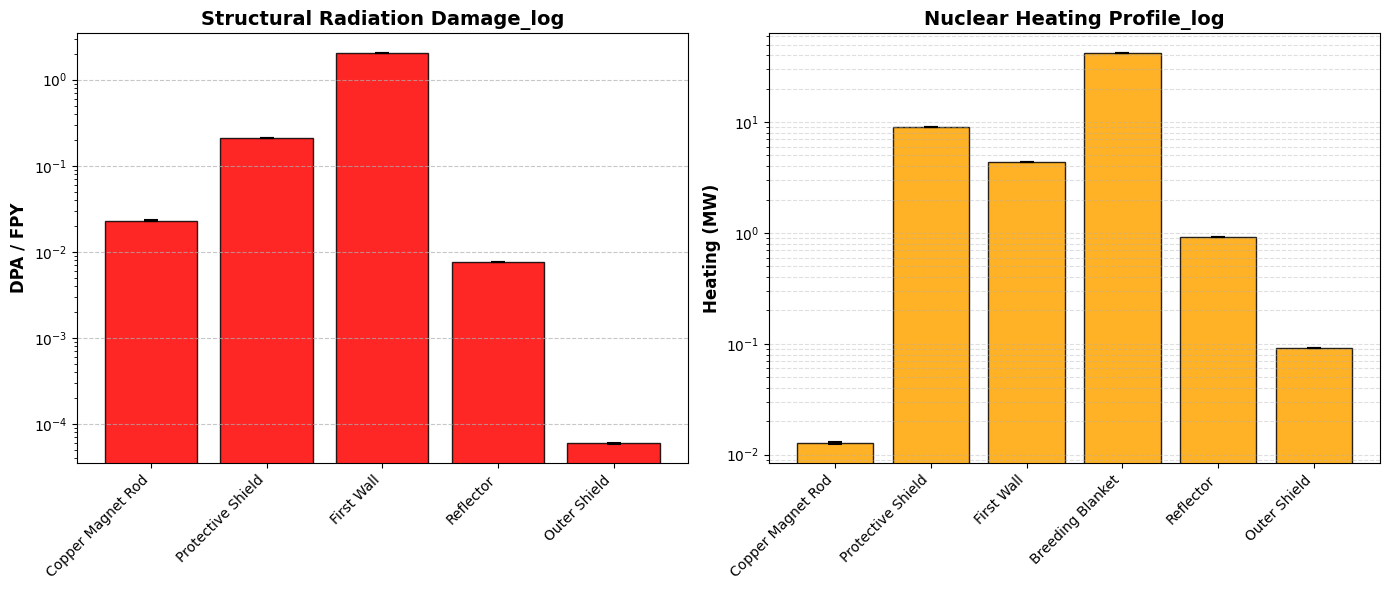

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

plt_type = 'log' # 'log' or 'linear'

# Graph 1- DPA per Full Power Year
#Breeding blanket ignored here. 
df_dpa = summary_df.copy()

# Force convert to numbers. Any string like '--' becomes NaN.
df_dpa['Avg_DPA_per_FPY'] = pd.to_numeric(df_dpa['Avg_DPA_per_FPY'], errors='coerce')
df_dpa['DPA_Std_Dev'] = pd.to_numeric(df_dpa['DPA_Std_Dev'], errors='coerce')


df_dpa = df_dpa.dropna(subset=['Avg_DPA_per_FPY'])

ax1.bar(df_dpa['Component'], df_dpa['Avg_DPA_per_FPY'], 
        yerr=df_dpa['DPA_Std_Dev'], capsize=5, color='red', edgecolor='black', alpha=0.85,
        error_kw={'elinewidth': 1.5, 'markeredgewidth': 1.5})

ax1.set_title(f"Structural Radiation Damage_{plt_type}", fontsize=14, fontweight='bold')
ax1.set_ylabel('DPA / FPY', fontsize=12, fontweight='bold')
ax1.set_xticks(range(len(df_dpa['Component'])))
ax1.set_xticklabels(df_dpa['Component'], rotation=45, ha='right')
ax1.set_yscale(plt_type)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

#-------------------------------------------------------------------------------------------------

# Graph 2: Nuclear Heating 
ax2.bar(summary_df['Component'], summary_df['Heating_MW'], 
        yerr=summary_df['Heating_MW_Std'], capsize=5, color='orange', edgecolor='black', alpha=0.85,
        error_kw={'elinewidth': 1.5, 'markeredgewidth': 1.5})

ax2.set_title(f"Nuclear Heating Profile_{plt_type}", fontsize=14, fontweight='bold')
ax2.set_ylabel('Heating (MW)', fontsize=12, fontweight='bold') 
ax2.set_xticks(range(len(summary_df['Component'])))
ax2.set_xticklabels(summary_df['Component'], rotation=45, ha='right')

ax2.set_yscale(plt_type)
ax2.grid(axis='y', which='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(TBR_DIR, f"Dpa_and_heating_profile_{plt_type}.png"), dpi=300, bbox_inches='tight')
plt.show()

### Consistency check: total heating vs. neutron + photon heating

The heating table uses the combined `All_Cells_Total` tally. This tally has no particle filter, so it scores the energy deposited by all particles in each cell. As an independent check, the separate neutron (`All_Cells_Neutron`) and photon (`All_Cells_Gamma`) heating tallies are added cell by cell and compared with it. Their sum should reproduce the total tally, so the ratio should be close to 1 for every cell (within statistical uncertainty). This confirms that the total heating includes both the neutron and the photon contributions, and that no component has been counted twice or missed. It also shows how much of the heating in each component comes from photons, which can be large in the dense tungsten regions.

In [33]:
with openmc.StatePoint(statepoint_filename) as sp:
    g_df = sp.get_tally(name='All_Cells_Gamma').get_pandas_dataframe()

g_heat = g_df[g_df['score'] == 'heating'].set_index('cell')['mean']
n_heat = df_n[df_n['score'] == 'heating'].set_index('cell')['mean']
tot    = heat_total_df['mean']

check = (n_heat + g_heat).to_frame('neutron+photon')
check['total_tally'] = tot
check['ratio'] = check['neutron+photon'] / check['total_tally']
print(check)

      neutron+photon   total_tally     ratio
cell                                        
1       3.584624e+03  3.587439e+03  0.999215
2       2.539310e+06  2.539370e+06  0.999976
3       1.214390e+06  1.214378e+06  1.000010
4       1.181311e+07  1.181321e+07  0.999992
5       2.600803e+05  2.600921e+05  0.999954
6       2.584301e+04  2.584291e+04  1.000004
7       0.000000e+00  0.000000e+00       NaN
8       0.000000e+00  0.000000e+00       NaN
9       0.000000e+00  0.000000e+00       NaN


**Result:** For all solid components (cells 1–6), neutron + photon heating matches the combined `All_Cells_Total` tally to within 0.08 % (ratios 0.9992–1.0000), so the total heating correctly includes both contributions. The largest difference is in the copper rod (cell 1, ratio 0.9992), which has the smallest heating and therefore the largest statistical uncertainty. The NaN values for the plasma, vacuum and graveyard cells (7, 8 and 9) are expected, because these cells contain no material and score zero heating. The agreement supports the use of the combined tally for the heating table.